In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/22/2022
# version ='1.0'

# Demo: Further Experiments on Comparison of Phase I methods

In book-convex-2004, two phase I methods were discussed. The first method is the basic method, the 'max' of infeasibilities in the following form,
\begin{equation}
\begin{array}{rcl}
\text{minimize} & s & \\
\text{subject to} & f_i(x) \leq s & ,i=1,...,m \\
& Ax=b \\
\end{array}
\end{equation}

Another method is the 'sum' of infeasibilities in the following form,
\begin{equation}
\begin{array}{rcl}
\text{minimize} & 1^Ts & \\
\text{subject to} & f_i(x)\leq s_i & ,i=1,...,m \\
& Ax=b & \\
& s \succeq 0 & \\
\end{array}
\end{equation}

In this demo, the two phase I methods are applied to an infeasible set of inequalities $Ax \preceq b$ with dimensions $m=1000,n=50$. 

After the application of the two methods, the feasibility problem is equivalent to the following LP problem with different $\tilde{A}, \tilde{b}, \tilde{c}$,
\begin{equation}
\begin{array}{rcl}
\text{minimize} & \tilde{c}^Tx \\
\text{subject to} & \tilde{A}x \preceq \tilde{b} \\
\end{array}
\end{equation}
where for the first method, 
$$ 
\begin{array}{rcl}
\tilde{A} & \leftarrow & \left[\begin{array}{cc}
A & -1_m 
\end{array} \right] \\ 
\tilde{b} & \leftarrow & b \\
\tilde{c} & \leftarrow & \left[\begin{array}{c}
0_n \\
1 \\
\end{array} \right]
\end{array}
$$

and for the second method,
$$ 
\begin{array}{rcl}
\tilde{A} & \leftarrow & \left[\begin{array}{cc}
A & -\mathbf{I}_m \\
0_{m\times n} & -\mathbf{I}_m \\ 
\end{array} \right] \\ 
\tilde{b} & \leftarrow & \left[\begin{array}{c}
b \\
0_{m} \\
\end{array} \right] \\
\tilde{c} & \leftarrow & \left[\begin{array}{c}
0_n \\
1_m \\
\end{array} \right]
\end{array}
$$

To construct a set of infeasible set of inequalities $Ax\preceq b$, the theorems of alternatives can be applied. Consider the system of linear inequalities $Ax\preceq b$, the strong alternative inequality system is therefore,
\begin{equation}
\begin{array}{ccc}
\lambda \succeq 0, & A^T\lambda = 0, & b^T\lambda < 0 \\
\end{array}
\end{equation}


Thus, $A, b$ can be generated to satisfy the strong alternative inequality system.

In [2]:
import numpy as np
from scipy.linalg import null_space
import matplotlib.pyplot as plt

 $f_0(x)=c^Tx$
 
 $\nabla f_0(x)=c$
 
 $\nabla^2 f_0(x)=0$

In [3]:
def my_f_0(x, t, A, b, c):
    """
    $f_0(x)=c^Tx$
    Refer to FlexibleLecture note
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, t, A, b, c):
    return True


def my_gradient_f_0(x, t, A, b, c):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return c


def my_hessian_f_0(x, t, A, b, c):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-1\sum(\log(b-Ax)$

$\nabla \phi(x)=A^T \dfrac{1}{b-Ax}$

$\nabla^2 \phi(x)=A^T \left[diag(\dfrac{1}{(b-Ax)^2})\right] A$

In [4]:
def my_phi(x, t, A, b, c):
    """
    $\phi(x)=-1\sum(\log(b-Ax)$
    Refer to FlexibleLecture note
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return -1 * np.sum(np.log(b - A @ x))


def my_phi_feasible(x, t, A, b, c):
    return np.all(b - A @ x > 0)


def my_gradient_phi(x, t, A, b, c):
    """
    $\nabla \phi(x)=A^T \dfrac{1}{b-Ax}$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    g = A.T @ (1 / (b - A @ x))
    return g


def my_hessian_phi(x, t, A, b, c):
    """
    $\nabla^2 \phi(x)=A^T \left[diag(\dfrac{1}{(b-Ax)^2})\right] A$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    diag = np.diag(np.squeeze((1 / (b - A @ x) ** 2)))
    hessian = A.T @ diag @ A
    return hessian

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [5]:
def my_f(x, t, A, b, c):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_f_0(x, t, A, b, c) + my_phi(x, t, A, b, c)


def my_f_feasible(x, t, A, b, c):
    return my_f_0_feasible(x, t, A, b, c) and my_phi_feasible(x, t, A, b, c)


def my_gradient_f(x, t, A, b, c):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_gradient_f_0(x, t, A, b, c) + my_gradient_phi(x, t, A, b, c)


def my_hessian_f(x, t, A, b, c):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param A:
    :param b:
    :param c:
    :return:
    """
    return t * my_hessian_f_0(x, t, A, b, c) + my_hessian_phi(x, t, A, b, c)

 Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [6]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param x:
    :param args:
    :return:
    """
    (t, A, b, c) = args
    (m, n) = A.shape
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt_w = np.linalg.inv(KKT) @ (-1 * residual)
        x_nt = x_nt_w[0: n]
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invisible')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [7]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [8]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, A, b, c, max_newton_iteration=100):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param A:
    :param b:
    :param c:
    :param max_newton_iteration:
    :return:
    """
    x = x0
    args = (barrier_t, A, b, c)
    x_nt, decrement = my_newton_step_decrement(x, args)

    line_searching_steps = []
    fx = [my_f(x, *args)]
    decrements = [decrement]

    iteration = 0
    while decrement / 2 > epsilon:
        t = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        #print(r'iteration={}, decrement={}, t={}'.format(iteration, decrement, t))

        x_next = x + t * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        line_searching_steps.append(t)
        fx.append(my_f(x, *args))
        decrements.append(decrement)

        iteration = iteration + 1

        if iteration > max_newton_iteration:
            print('Error: Newton method not converged!')
            break

    #print(r'iteration={}, decrement={}'.format(iteration, decrement))
    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, line_searching_steps

To construct a set of infeasible set of inequalities $Ax\preceq b$ by the theorems of alternatives

Refer to FlexibleLecture note

In [9]:
def get_infeasible_A_b(n, m):
    """
    To construct a set of infeasible set of inequalities $Ax\preceq b$ by the theorems of alternatives
    Refer to FlexibleLecture note
    :param n: the dimension of x in the inequalities $Ax\preceq b$
    :param m:
    :return:
    """
    if m < n:
        raise RuntimeError('Ax<= b with m < n is not supported.')

    lambda_ = np.random.uniform(low=0, high=1, size=(m, 1))
    ns = null_space(lambda_.T)

    A = ns[:, 0:n]
    if not np.allclose(A.T @ lambda_, 0):
        raise RuntimeError('A^T lambda should be zero')

    dial = 0
    while True:
        b = np.random.uniform(low=-1, high=1, size=(m, 1))
        if (lambda_.T @ b).item() < 0:
            break
        else:
            dial += 1
            print('Info: Here is the {}-th dial in getting b satisfying b^T * lambda < 0'.format(dial))

    return A, b

Get the model parameter A_hat, b_hat, c_hat, xs for the Phase I method from the inequality Ax<b

In [10]:
def get_A_b_c_xs_hat(A, b, option):
    """
    Get the model parameter A_hat, b_hat, c_hat, xs for the Phase I method from the inequality Ax<b
    :param A:
    :param b:
    :param option: 'max', 'sum'
    :return:
    """
    (m, n) = A.shape
    if option == "max":
        n_hat = n + 1  # additional variable s
        c_hat = np.zeros((n_hat, 1))
        c_hat[-1] = 1
        A_hat = np.block([[A, -np.ones((m, 1))]])
        b_hat = b
        x0 = np.zeros((n, 1))
        s0 = np.max(-b_hat) + 0.1  # plus 0.1 so that Ax <= d + s is feasible at [x0, s0]
        xs0 = np.block([[x0], [s0]])
        if not np.all(A_hat @ xs0 < b_hat):
            raise RuntimeError('it is requiring the start point is strictly feasible!')
        return A_hat, b_hat, c_hat, xs0
    elif option == "sum":
        c_hat = np.block([[np.zeros((n, 1))], [np.ones((m, 1))]])
        A_hat = np.block([[A, -np.eye(m)], [np.zeros(A.shape), -np.eye(m)]])
        b_hat = np.block([[b], [np.zeros((m, 1))]])
        x0 = np.zeros((n, 1))
        s0 = -b + (np.max(np.abs(b)) + 0.1) * np.ones((m, 1))  # so that Ax <= d + s is feasible at x0, s0
        xs0 = np.block([[x0], [s0]])
        if not np.all(A_hat @ xs0 < b_hat):
            raise RuntimeError('it is requiring the start point is strictly feasible!')
        return A_hat, b_hat, c_hat, xs0
    else:
        raise RuntimeError('only max and sum option is supported.')

plot the figure comparing the distributions of the inequalities $b_i-a_i^Tx$ for
    an infeasible set of m inequalities $a_i^Tx\leq b_i$, $x in \mathbf{R}^n$, where n=m/2

In [11]:
def plot_comparison_result_figure(seed, m, mu=100):
    """
    plot the figure comparing the distributions of the inequalities $b_i-a_i^Tx$ for
    an infeasible set of m inequalities $a_i^Tx\leq b_i$, $x in \mathbf{R}^n$, where n=m/2
    :param mu:
    :param m:
    :param seed:
    :return:
    """
    plt.figure(figsize=(12, 4))
    ax = plt.subplot(1, 1, 1)
    options = ["max", "sum"]
    for opt_i, option in enumerate(options):
        np.random.seed(seed)

        n = int(m / 2)
        n_hat = n + 1

        A, b = get_infeasible_A_b(n, m)
        A_hat, b_hat, c_hat, xs0 = get_A_b_c_xs_hat(A, b, option)

        alpha = 0.01
        beta = 0.5
        epsilon = 1e-5
        duality_gap_epsilon = n_hat * 1e-6

        t0 = 1
        t = t0

        args = (t, A_hat, b_hat, c_hat)
        xs_t, n_iter, f_xs, decrement, t_xs = centering_step(xs0, epsilon, alpha, beta, *args)
        xs_0 = xs_t
        t = mu * t

        accumulate_iteration = 0

        while True:
            args = (t, A_hat, b_hat, c_hat)

            xs_t, n_iter, f_xs, decrement, t_xs = centering_step(xs_0, epsilon, alpha, beta, *args)
            xs_0 = xs_t
            accumulate_iteration = accumulate_iteration + n_iter

            if m / t < duality_gap_epsilon:
                break
            else:
                t = mu * t

        x = xs_0[0:n]
        d = np.squeeze(A @ x - b)
        ds = np.sort(d)
        ax.plot(ds, np.linspace(0, 1, len(d), endpoint=False), label='method={}'.format(option))

    ax.grid()
    ax.legend()
    ax.set_xlabel(r'$a_ix-b_i$')
    ax.set_ylabel('empirical cdf')
    plt.show()

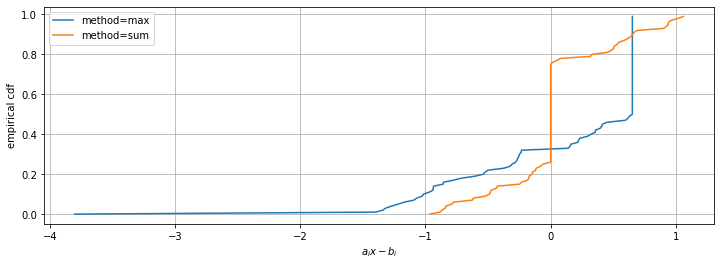

In [12]:
if __name__ == "__main__":
    plot_comparison_result_figure(seed=1, m=100)